# ICAIC Mock Problem — Classify a Damaged Inspection Image

## Problem statement

A factory camera photographs a symbol on each part. The symbol is a **ring**, a **plus**, or an **X**. Camera noise makes the image grainy, and a rectangular patch of pixels is missing. Your task is to **classify the symbol from the damaged image**.

You have **150 labelled training images** and **6,000 unlabelled images** for pretraining. Can learning to reconstruct missing pixels help your classifier learn from fewer labels?

## Inputs and outputs

Each image is grayscale and measures **40 × 40 pixels**.

| Field | Description | Use |
|---|---|---|
| `damaged` | Noisy image with a rectangular patch set to zero | Model input |
| `missing` | Boolean mask. `True` marks a missing pixel. | Model input |
| `clean` | Original image before noise and masking | Reconstruction target during pretraining |
| `y` | Class label. `0` = ring, `1` = plus, `2` = X. | Classification target for labelled examples |

Your classifier receives `damaged` and `missing` and returns **three raw logits per image**, one per class. Choose the class with the highest logit.

## Evaluation

- **Classification:** Use **macro F1**, which gives each symbol class equal weight.
- **Reconstruction:** Use **mean squared error (MSE)** between the reconstructed and clean images, averaged over **missing pixels only**.
- **Comparison:** Train one classifier from scratch on the 150 labelled images. Pretrain a second encoder by reconstructing missing pixels, then fine-tune it on those same 150 images. Compare both classifiers on the same validation split.
- **Final scores:** Report macro F1 separately on images from the original camera and from a new camera with a different background pattern and more noise.

## data generation

In [1]:
# @title
import torch


def make_split(n, seed, *, camera=0, labelled=True):
    rng = torch.Generator().manual_seed(seed)
    size = 40
    labels = (torch.arange(n) % 3)[torch.randperm(n, generator=rng)]

    row = torch.arange(size).view(1, size, 1)
    col = torch.arange(size).view(1, 1, size)
    dy = row - torch.randint(13, 27, (n, 1, 1), generator=rng)
    dx = col - torch.randint(13, 27, (n, 1, 1), generator=rng)
    radius = torch.randint(7, 11, (n, 1, 1), generator=rng)

    distance = (dx.square() + dy.square()).sqrt()
    ring = (distance - radius).abs() <= 1
    plus = ((dx.abs() <= 1) & (dy.abs() <= radius)) | (
        (dy.abs() <= 1) & (dx.abs() <= radius)
    )
    cross = ((dx - dy).abs() <= 1) | ((dx + dy).abs() <= 1)
    cross = cross & (dx.abs() <= radius) & (dy.abs() <= radius)
    symbol = torch.stack((ring, plus, cross), dim=1)[torch.arange(n), labels]

    brightness = 0.10 + 0.25 * torch.rand(n, 1, 1, generator=rng)
    contrast = 0.35 + 0.40 * torch.rand(n, 1, 1, generator=rng)
    stripe_axis = col if camera == 0 else row
    phase = 6.28 * torch.rand(n, 1, 1, generator=rng)
    clean = (brightness + contrast * symbol + 0.08 *
             torch.sin(stripe_axis / 3 + phase)).clamp(0, 1)

    top = torch.randint(9, 23, (n, 1, 1), generator=rng)
    left = torch.randint(9, 23, (n, 1, 1), generator=rng)
    side = torch.randint(8, 15, (n, 1, 1), generator=rng)
    missing = (row >= top) & (row < top + side) & (
        col >= left
    ) & (col < left + side)

    noise_std = 0.08 if camera == 0 else 0.16
    noise = noise_std * torch.randn(clean.shape, generator=rng)
    damaged = (clean + noise).clamp(0, 1).masked_fill(missing, 0.0)

    split = {
        "damaged": damaged.unsqueeze(1),  # [N, 1, 40, 40]
        "missing": missing.unsqueeze(1),  # [N, 1, 40, 40]
        "clean": clean.unsqueeze(1),      # [N, 1, 40, 40]
    }
    if labelled:
        split["y"] = labels
    return split

pretrain = make_split(6_000, seed=10, labelled=False)
train = make_split(150, seed=20)
val = make_split(450, seed=30)
test_same = make_split(900, seed=40)
test_new_camera = make_split(900, seed=50, camera=1)

print("data generation done!")

data generation done!


## Task
1. Train a classifier from scratch. Build a small custom nn.Module and train it on the 150 labelled examples. Implement the DataLoader, device transfers, training loop, validation, and checkpoint selection. Record validation macro F1.
2. Pretrain an encoder by reconstructing the missing pixels. Use pretrain. Build an encoder and a decoder that returns a 40×40 image. Compute the loss only where missing is True. Compare reconstruction MSE with a simple rule that fills the block with the mean of the visible pixels.
3. Reuse the encoder for classification. Attach a classification head. First freeze the encoder and train only the head. Then try fine-tuning the encoder. Use the same 150 labelled images and the same validation split for all three classifier runs.
4. Explain what helped. Inspect a few reconstructed images and a confusion matrix. Did pretraining improve classification? Which pair of symbols gets confused most often? Once you choose the final model, report macro F1 on both test sets separately.

In [2]:
print(pretrain.keys())
print(train.keys())
print(val.keys())
print(test_same.keys())
print(test_new_camera.keys())

dict_keys(['damaged', 'missing', 'clean'])
dict_keys(['damaged', 'missing', 'clean', 'y'])
dict_keys(['damaged', 'missing', 'clean', 'y'])
dict_keys(['damaged', 'missing', 'clean', 'y'])
dict_keys(['damaged', 'missing', 'clean', 'y'])


In [3]:
print(len(train['damaged']))
print(len(train['missing']))
print(len(train['clean']))

150
150
150


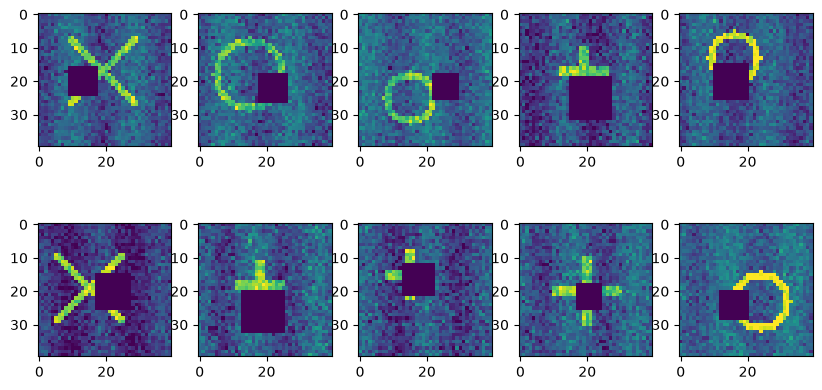

In [4]:
# prelim eda
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10,5))

for i, ax in enumerate(axes.flat):
  img_arr = train['damaged'][i].squeeze(0).numpy()
  ax.imshow(img_arr)

In [5]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
from torch.optim import AdamW

X_train, y_train = train['damaged'], train['y']
X_test, y_test = val['damaged'], val['y']

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_test, y_test)


X_train, X_missing, y_train = train['damaged'], train['missing'], train['y']
train_dataset = TensorDataset(X_train, X_missing, y_train)

X_test, X_miss_t, y_test = val['damaged'], val['missing'], val['y']
val_dataset = TensorDataset(X_test, X_miss_t, y_test)


In [6]:
print(X_train[0].shape)

torch.Size([1, 40, 40])


In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"

loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=True)

# build custom CNN model trains on
# nn.Sequential

# train loop, loop over loader

def build_model():
  model = nn.Sequential(
      nn.Conv2d(2, 16, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(16),
      nn.ReLU(),
      nn.Conv2d(16, 16, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(16),
      nn.ReLU(),
      nn.AdaptiveAvgPool2d(20),
      nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
      nn.AdaptiveAvgPool2d(1),
      nn.Flatten(1),
      nn.Linear(32, 3)
  )
  return model

In [8]:
import numpy as np
from sklearn.metrics import f1_score
from copy import deepcopy

def eval_model(model):
  # validation loop
  model.eval()

  avg_loss = 0

  preds = []
  targ = []

  with torch.no_grad():
    for damaged, mask, target in val_loader:
      damaged = damaged.to(device)
      mask = mask.to(device)
      target = target.to(device)

      logits = model(torch.cat((damaged, mask), dim=1))
      y_pred = logits.argmax(dim=1)

      # loss = loss_func(logits, target)
      # avg_loss += loss * len(inputs)

      preds.extend(y_pred.cpu().tolist())
      targ.extend(target.cpu().tolist())

  # print(f"Val Avg Loss: {avg_loss/len(val_dataset)}")

  return f1_score(preds, targ, average="macro")


epochs = 151
avg_loss = 0

torch.manual_seed(42)
model = build_model()
model = model.to(device)

loss_func = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=1e-3)

best_model = None
best_f1 = float("-inf")
best_epoch = 0
y_pred = None

model.train()
for i in range(epochs):
  avg_loss = 0
  # print("="*50)
  # print(f"Epoch {i}")
  for damaged, mask, targets in loader:
    optimizer.zero_grad()

    damaged = damaged.to(device)
    mask = mask.to(device)
    targets = targets.to(device)

    logits = model(torch.cat((damaged, mask), dim=1))

    loss = loss_func(logits, targets)
    loss.backward()
    optimizer.step()

    avg_loss += loss * len(damaged)

    y_pred = logits.argmax(dim=1)

  f1 = eval_model(model)

  if f1 > best_f1:
    best_epoch = i
    best_f1 = f1
    best_model = deepcopy(model.state_dict())
    print(f"updated best f1: {f1}, epoch {i}")


print("done training!")

updated best f1: 0.16666666666666666, epoch 0
updated best f1: 0.2596629187648019, epoch 1
updated best f1: 0.2833333333333334, epoch 2
updated best f1: 0.29207984840311174, epoch 3
updated best f1: 0.413822418978483, epoch 6
updated best f1: 0.4323535803226643, epoch 8
updated best f1: 0.4450218822842397, epoch 12
updated best f1: 0.45941236493416143, epoch 14
updated best f1: 0.5215343680445269, epoch 19
updated best f1: 0.5224862440699354, epoch 25
updated best f1: 0.6025179324397579, epoch 26
updated best f1: 0.6339909527029203, epoch 28
updated best f1: 0.6546398839954137, epoch 29
updated best f1: 0.6576362054103146, epoch 31
updated best f1: 0.6642322687476443, epoch 32
updated best f1: 0.7049066273057841, epoch 34
updated best f1: 0.8328553349357787, epoch 35
updated best f1: 0.888607327631718, epoch 40
updated best f1: 0.9183380693191658, epoch 43
updated best f1: 0.9557947798330746, epoch 44
updated best f1: 0.9558095292403613, epoch 48
updated best f1: 0.9668530883220149, ep

In [9]:
model.load_state_dict(best_model)
# print(model)
# print(best_epoch)
f1 = eval_model(model)

print(f"Best epoch: {best_epoch}")
print(f"Saved F1:    {best_f1:.4f}")
print(f"Restored F1: {f1:.4f}")


Best epoch: 124
Saved F1:    0.9956
Restored F1: 0.9956


2. Pretrain an encoder by reconstructing the missing pixels. Use pretrain. Build an encoder and a decoder that returns a 40×40 image. Compute the loss only where missing is True. Compare reconstruction MSE with a simple rule that fills the block with the mean of the visible pixels.
3. Reuse the encoder for classification. Attach a classification head. First freeze the encoder and train only the head. Then try fine-tuning the encoder. Use the same 150 labelled images and the same validation split for all three classifier runs.
4. Explain what helped. Inspect a few reconstructed images and a confusion matrix. Did pretraining improve classification? Which pair of symbols gets confused most often? Once you choose the final model, report macro F1 on both test sets separately.

In [10]:
def build_encoder():
  encoder = nn.Sequential(
      nn.Conv2d(2, 16, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(16),
      nn.ReLU(),
      nn.Conv2d(16, 16, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(16),
      nn.ReLU(),
      nn.AdaptiveAvgPool2d(20),
      nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
  )
  return encoder

def build_decoder():
  decoder = nn.Sequential(
      nn.Upsample(scale_factor=2),
      nn.Conv2d(32, 16, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(16),
      nn.ReLU(),
      nn.Conv2d(16, 1, kernel_size=3, stride=1, padding=1),
  )
  return decoder

Each image is grayscale and measures **40 × 40 pixels**.

| Field | Description | Use |
|---|---|---|
| `damaged` | Noisy image with a rectangular patch set to zero | Model input |
| `missing` | Boolean mask. `True` marks a missing pixel. | Model input |
| `clean` | Original image before noise and masking | Reconstruction target during pretraining |
| `y` | Class label. `0` = ring, `1` = plus, `2` = X. | Classification target for labelled examples |

Your classifier receives `damaged` and `missing` and returns **three raw logits per image**, one per class. Choose the class with the highest logit.

In [11]:
X_damaged, X_mask, y_clean = pretrain["damaged"], pretrain["missing"], pretrain["clean"]

print(X_damaged.shape)

torch.Size([6000, 1, 40, 40])


In [12]:
torch.manual_seed(42)

encoder = build_encoder()
decoder = build_decoder()

autoencoder = nn.Sequential(
    encoder,
    decoder
)

autoencoder.to(device)

Sequential(
  (0): Sequential(
    (0): Conv2d(2, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): AdaptiveAvgPool2d(output_size=20)
    (7): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
  )
  (1): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Conv2d(16, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
)

Use **mean squared error (MSE)** between the reconstructed and clean images, averaged over **missing pixels only**.

In [13]:
from sklearn.model_selection import train_test_split

d_train, d_test, m_train, m_test, c_train, c_test = train_test_split(
    X_damaged, X_mask, y_clean,
    test_size=0.1,
    random_state=42
)



pretrain_train = TensorDataset(d_train, m_train, c_train)
pretrain_val = TensorDataset(d_test, m_test, c_test)

pretrain_loader = DataLoader(pretrain_train, batch_size=32, shuffle=True)
pretrain_val_loader = DataLoader(pretrain_val, batch_size=32, shuffle=True)

In [14]:
# autoencoder_eval(autoencoder) for autoencoder model selection

def autoencoder_eval(autoencoder):
  autoencoder.eval()

  tot_squared_error = 0
  tot_missing_pixels = 0

  with torch.no_grad():
    for damaged, mask, clean in pretrain_val_loader:
      damaged = damaged.to(device)
      mask = mask.to(device)
      clean = clean.to(device)

      reconstructed = autoencoder(torch.cat((damaged, mask), dim=1))

      squared = (reconstructed-clean)**2

      tot_squared_error += (squared * mask).sum().item()
      tot_missing_pixels += mask.sum().item()

  if tot_missing_pixels == 0:
    tot_missing_pixels = 1

  return tot_squared_error/tot_missing_pixels

In [15]:
from copy import deepcopy

optimizer = AdamW(params=autoencoder.parameters(), lr=1e-3)

epochs = 100
best_model = None
best_loss = float("inf")
best_epoch = None

for i in range(epochs):
  autoencoder.train()

  epoch_sq_err = 0
  epoch_missing_px = 0

  for damaged, mask, clean in pretrain_loader:
    damaged = damaged.to(device)
    mask = mask.to(device)
    clean = clean.to(device)

    optimizer.zero_grad()
    reconstructed = autoencoder(torch.cat((damaged, mask), dim=1))

    squared = (reconstructed-clean)**2
    batch_sq_err = (mask * squared).sum()
    batch_missing_px = mask.sum()

    batch_loss = batch_sq_err/batch_missing_px.clamp_min(1)

    batch_loss.backward()
    optimizer.step()

    epoch_sq_err += batch_sq_err.item()
    epoch_missing_px += batch_missing_px.item()

  val_loss = autoencoder_eval(autoencoder)
  epoch_loss = epoch_sq_err/max(epoch_missing_px,1)

  print(f"epoch {i} train loss: {epoch_loss}")

  if val_loss < best_loss:
    best_loss = val_loss
    best_model = deepcopy(autoencoder.state_dict())
    best_epoch = i
    print(f"updated best model (epoch {i}): val loss = {val_loss}")


epoch 0 train loss: 0.04937010495780699
updated best model (epoch 0): val loss = 0.04009077886477708
epoch 1 train loss: 0.03886066760872447
updated best model (epoch 1): val loss = 0.03618657738350931
epoch 2 train loss: 0.03525094022811488
updated best model (epoch 2): val loss = 0.0351098146539182
epoch 3 train loss: 0.03377527371028341
updated best model (epoch 3): val loss = 0.03180778741991146
epoch 4 train loss: 0.032182893307277236
updated best model (epoch 4): val loss = 0.03066398603139045
epoch 5 train loss: 0.031057008498103736
updated best model (epoch 5): val loss = 0.02941501698251712
epoch 6 train loss: 0.030328144318831098
updated best model (epoch 6): val loss = 0.02870539636283938
epoch 7 train loss: 0.02947159911582849
updated best model (epoch 7): val loss = 0.02839727814541726
epoch 8 train loss: 0.02878439173584628
updated best model (epoch 8): val loss = 0.02772644227527264
epoch 9 train loss: 0.028227039509257906
updated best model (epoch 9): val loss = 0.02733

In [16]:
autoencoder.load_state_dict(best_model)
print(autoencoder_eval(autoencoder))

pretrained_encoder = deepcopy(encoder)

print(f"best epoch: {best_epoch}")
print(f"best loss: {best_loss}")

0.0207834992533756
best epoch: 91
best loss: 0.020783499354337587


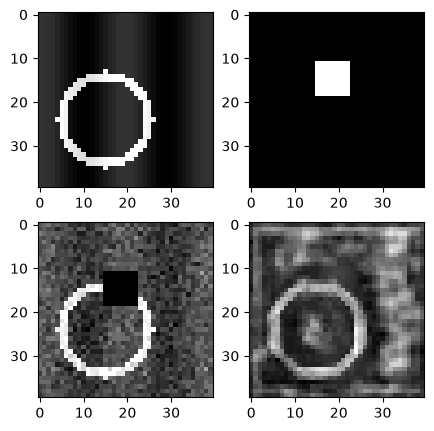

In [17]:
autoencoder.eval()
tot_squared_error = 0
tot_missing_pixels = 0

c = None
m = None
d = None
r = None
torch.manual_seed(4)       								 
with torch.no_grad():
    for damaged, mask, clean in pretrain_val_loader:

      
      damaged = damaged.to(device)
      mask = mask.to(device)
      clean = clean.to(device)

      c = clean.cpu()[:1].squeeze().tolist()
      d = damaged.cpu()[:1].squeeze().tolist()
      m = mask.cpu()[:1].squeeze().tolist()

      reconstructed = autoencoder(torch.cat((damaged, mask), dim=1))

      squared = (reconstructed-clean)**2

      tot_squared_error += (squared * mask).sum().item()
      tot_missing_pixels += mask.sum().item()

      r = reconstructed[:1].squeeze().tolist()
        
      break


imgs = [c, m, d, r]
fig, axes = plt.subplots(2, 2, figsize=(5, 5))

for img, ax in zip(imgs, axes.flat):
    ax.imshow(img, cmap="grey")

In [18]:
def build_pretrained():
    pretrained_model = nn.Sequential(
        encoder, 
        nn.AdaptiveAvgPool2d(1),
        nn.Flatten(1),
        nn.Linear(32, 3)
    )
    return pretrained_model

In [19]:
def eval_model(pretrained_model):
    pretrained_model.eval()

    preds = []
    targ = []

    with torch.no_grad():
        for damaged, mask, target in val_loader:
            damaged = damaged.to(device) 
            mask = mask.to(device) 
            target = target.to(device) 
            
            logits = pretrained_model(torch.cat((damaged, mask), dim=1))
            y_pred = logits.argmax(dim=1)
            
            preds.extend(y_pred.cpu().tolist())
            targ.extend(target.cpu().tolist())
            
    return f1_score(preds, targ, average="macro")



pretrained_model = build_pretrained()

optimizer = AdamW(params=pretrained_model.parameters(), lr=1e-3)
loss_func = nn.CrossEntropyLoss()
pretrained_model.to(device)


epoch_loss = 0

epochs = 100

best_model = None
best_epoch = 0
best_f1 = float("-inf")

for i in range(epochs):
    pretrained_model.train()
    
    y_pred = []
    actual = []
    for damaged, mask, target in loader: 
        damaged = damaged.to(device)
        mask = mask.to(device) 
        target = target.to(device) 
    
        optimizer.zero_grad()
    
        logits = pretrained_model(torch.cat((damaged, mask), dim=1))
    
        loss = loss_func(logits, target)
        y_p = logits.argmax(dim=1)
    
        loss.backward()
        optimizer.step()
    
        epoch_loss += loss.item() * len(damaged)
        
        y_pred.extend(y_p.cpu())
        actual.extend(target.cpu())
    
    epoch_loss /= len(loader.dataset)

    f1 = eval_model(pretrained_model)

    if f1 > best_f1:
        best_f1 = f1
        best_epoch = i
        best_model = deepcopy(pretrained_model.state_dict())
        print(f"epoch {i}")
        print(f"new best f1: {f1}")
    
    print(f"f1_score: {f1}")
    f1 = f1_score(actual, y_pred, average="macro")

epoch 0
new best f1: 0.5233119745010703
f1_score: 0.5233119745010703
epoch 1
new best f1: 0.6796403253493066
f1_score: 0.6796403253493066
epoch 2
new best f1: 0.7702874331550801
f1_score: 0.7702874331550801
epoch 3
new best f1: 0.8262965507358851
f1_score: 0.8262965507358851
epoch 4
new best f1: 0.8669936489970446
f1_score: 0.8669936489970446
epoch 5
new best f1: 0.886841161573877
f1_score: 0.886841161573877
f1_score: 0.8789635990733773
epoch 7
new best f1: 0.9237545351970141
f1_score: 0.9237545351970141
f1_score: 0.8842567739329684
f1_score: 0.9085224905781756
epoch 10
new best f1: 0.9733772320653621
f1_score: 0.9733772320653621
f1_score: 0.9401738064873123
f1_score: 0.924457952043527
f1_score: 0.966695140608184
f1_score: 0.8503226893854356
epoch 15
new best f1: 0.9911095305832148
f1_score: 0.9911095305832148
f1_score: 0.8704289045310137
f1_score: 0.966695140608184
f1_score: 0.6601348356920451
f1_score: 0.982263569145896
epoch 20
new best f1: 0.9977777530861455
f1_score: 0.99777775308

In [20]:
pretrained_model.load_state_dict(best_model)
print(f"best epoch: {best_epoch}")
print(f"best f1: {best_f1}")

best epoch: 57
best f1: 1.0


In [82]:
def build_model():
  model = nn.Sequential(
      nn.Conv2d(2, 16, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(16),
      nn.ReLU(),
      nn.Conv2d(16, 16, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(16),
      nn.ReLU(),
      nn.AdaptiveAvgPool2d(20),
      nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
  )
  return model

def classifier_head(feature_extract):
    model = nn.Sequential(
        feature_extract, 
        nn.AdaptiveAvgPool2d(1), 
        nn.Flatten(1),
        nn.Linear(32, 3)
    )
    return model
    

scratch_model = classifier_head(build_model())
frozen_model = classifier_head(deepcopy(pretrained_encoder))
finetuned_model = classifier_head(deepcopy(pretrained_encoder))

print("made models")

made models


In [99]:
def eval_model(model, val_loader):
    model.to(device)
    model.eval()

    loss_func = nn.CrossEntropyLoss()
    macro_f1 = 0

    tot_pred = []
    tot_actual = []

    with torch.no_grad():
        for damaged, mask, target in val_loader:
            damaged = damaged.to(device)
            mask = mask.to(device)
            target = target.to(device)

            logits = model(torch.cat((damaged, mask), dim=1))
            y_pred = logits.argmax(dim=1)

            tot_pred.extend(y_pred.cpu().tolist())
            tot_actual.extend(target.cpu().tolist())

        macro_f1 = f1_score(tot_pred, tot_actual, average="macro")

    return macro_f1
            
def train_model(model, loader, frozen=False, epochs=100):
    best_epoch = None
    best_f1 = float("-inf")
    best_model = None
    
    model.to(device)
    
    if frozen: 
        model[0].requires_grad_(False)
    
    loss_func = nn.CrossEntropyLoss()
    optimizer = AdamW(params=(p for p in model.parameters() if p.requires_grad), lr=1e-3)

    for epoch in range(epochs):
        model.train()
        
        if frozen:
            model[0].eval()

        for damaged, mask, target in loader: 
            optimizer.zero_grad()

            damaged = damaged.to(device)
            mask = mask.to(device)
            target = target.to(device)

            logits = model(torch.cat((damaged, mask), dim=1))
            y_pred = logits.argmax(dim=1)

            loss = loss_func(logits, target)

            loss.backward()
            optimizer.step()

        f1 = eval_model(model, val_loader)

        if f1 > best_f1:
            best_f1 = f1
            best_model = deepcopy(model.state_dict())
            best_epoch = epoch

    return best_model, best_epoch, best_f1

In [100]:
s_model, s_ep, s_loss = train_model(model=scratch_model, loader=loader)
froz_model, froz_ep, froz_loss = train_model(model=frozen_model, loader=loader, frozen=True)
fine_model, fine_ep, fine_loss = train_model(model=finetuned_model, loader=loader)


scratch_model.load_state_dict(s_model)
frozen_model.load_state_dict(froz_model)
finetuned_model.load_state_dict(fine_model)

<All keys matched successfully>

In [101]:
print(s_ep, s_loss)
print(froz_ep, froz_loss)
print(fine_ep, fine_loss)

48 1.0
99 0.6202846791770487
40 1.0


In [102]:
# print(test_same)
# print(test_new_camera)
same_damaged, same_mask, same_y = test_same['damaged'], test_same['missing'], test_same['y']
new_damaged, new_mask, new_y = test_new_camera['damaged'], test_new_camera['missing'], test_new_camera['y']

same_data = TensorDataset(same_damaged, same_mask, same_y)
new_data = TensorDataset(new_damaged, new_mask, new_y)

same_loader = DataLoader(same_data, batch_size=8, shuffle=True)
new_loader = DataLoader(new_data, batch_size=8, shuffle=True)

In [103]:
models = [scratch_model, frozen_model, finetuned_model]
model_name = ["scratch_model", "frozen_model", "finetuned_model"]

performance = dict()
    
for model, name in zip(models, model_name):
    same_loss = eval_model(model, same_loader)
    new_loss = eval_model(model, new_loader)

    performance[name] = [same_loss, new_loss]

print(performance)

{'scratch_model': [0.9988888858024606, 0.4562269984030097], 'frozen_model': [0.6209315375982043, 0.33426700668385867], 'finetuned_model': [1.0, 0.1713599192178281]}


In [110]:
new_damaged, new_mask, new_y, new_clean = test_new_camera['damaged'][:1].squeeze(), test_new_camera['missing'][:1].squeeze(), test_new_camera['y'][:1], test_new_camera['clean'][:1].squeeze()
